In [15]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_log_error

print("Libraries imported successfully")

Libraries imported successfully


In [16]:
train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")

print("Train shape:", train.shape)
print("Test shape:", test.shape)

Train shape: (10886, 12)
Test shape: (6493, 9)


In [17]:
# Convert datetime
train["datetime"] = pd.to_datetime(train["datetime"])
test["datetime"] = pd.to_datetime(test["datetime"])

# Extract useful time features
for df in [train, test]:
    df["year"] = df["datetime"].dt.year
    df["month"] = df["datetime"].dt.month
    df["day"] = df["datetime"].dt.day
    df["hour"] = df["datetime"].dt.hour
    df["day_of_week"] = df["datetime"].dt.dayofweek

    # Weekend indicator
    df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)

    # Peak-hour indicator
    df["peak_hour"] = (
        (
            (df["day_of_week"] < 5) &
            (df["hour"].isin([7, 8, 9, 17, 18, 19]))
        )
        |
        (
            (df["day_of_week"] >= 5) &
            (df["hour"].between(10, 18))
        )
    ).astype(int)

print("Feature engineering completed")

Feature engineering completed


In [18]:
# Target variable
y = train["count"]

# Remove target leakage and unnecessary datetime column
X = train.drop(
    columns=["count", "casual", "registered", "datetime"]
)

# Test data
test_features = test.drop(columns=["datetime"])

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Test features shape:", test_features.shape)

X shape: (10886, 15)
y shape: (10886,)
Test features shape: (6493, 15)


In [19]:
X = pd.get_dummies(
    X,
    columns=["season", "weather"],
    drop_first=False
)

test_features = pd.get_dummies(
    test_features,
    columns=["season", "weather"],
    drop_first=False
)

# Ensure train and test have identical feature columns
X, test_features = X.align(
    test_features,
    join="left",
    axis=1,
    fill_value=0
)

print("Final X shape:", X.shape)
print("Final test shape:", test_features.shape)

Final X shape: (10886, 21)
Final test shape: (6493, 21)


In [20]:
print("Missing values in X:", X.isnull().sum().sum())
print("Missing values in test:", test_features.isnull().sum().sum())

Missing values in X: 0
Missing values in test: 0


In [21]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_valid))

Training samples: 8708
Validation samples: 2178


In [22]:
def rmsle(y_true, y_pred):
    y_pred = np.maximum(y_pred, 0)
    
    return np.sqrt(
        mean_squared_log_error(y_true, y_pred)
    )

In [23]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_pred = linear_model.predict(X_valid)

linear_score = rmsle(
    y_valid,
    linear_pred
)

print("Linear Regression RMSLE:", linear_score)

Linear Regression RMSLE: 1.273642155962089


In [24]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_valid)

rf_score = rmsle(
    y_valid,
    rf_pred
)

print("Random Forest RMSLE:", rf_score)

Random Forest RMSLE: 0.3281389526975628


In [25]:
gb_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=5,
    random_state=42
)

gb_model.fit(X_train, y_train)

gb_pred = gb_model.predict(X_valid)

gb_score = rmsle(
    y_valid,
    gb_pred
)

print("Gradient Boosting RMSLE:", gb_score)

Gradient Boosting RMSLE: 0.4527449249559869


In [26]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "RMSLE": [
        linear_score,
        rf_score,
        gb_score
    ]
})

results = results.sort_values("RMSLE").reset_index(drop=True)

results

,Model,RMSLE
0,Random Forest,0.328139
1,Gradient Boosting,0.452745
2,Linear Regression,1.273642


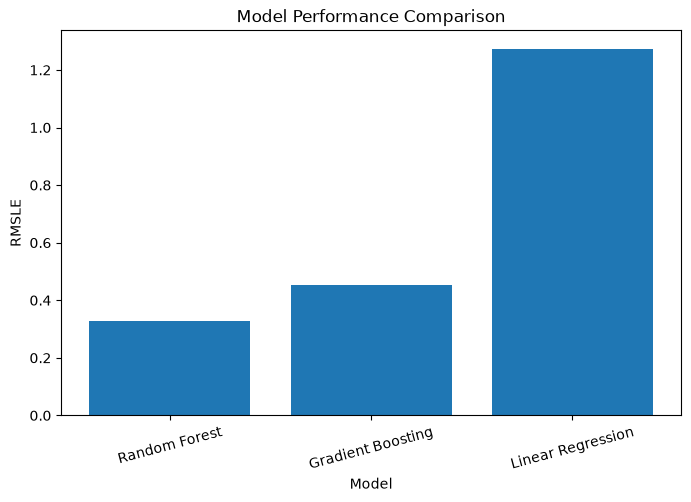

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    results["Model"],
    results["RMSLE"]
)

plt.xlabel("Model")
plt.ylabel("RMSLE")
plt.title("Model Performance Comparison")
plt.xticks(rotation=15)

plt.show()

In [28]:
import os

os.makedirs("../results", exist_ok=True)

results.to_csv(
    "../results/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully.")

Model comparison saved successfully.
